# arXiv embeddings at scale

This notebook consumes the sample and prepared text vectors made by [Prepare the arXiv dataset](../data/arxiv/prepare_dataset.ipynb). It fits one UMAP embedding and one multilevel-initialized IMSTE embedding with an integrated density-gravity phase. The estimator can return both the pre-gravity and final gravity coordinates. Gravity is feature-space based; UMAP coordinates are never used to initialize IMSTE.


## 1. Load the prepared dataset

Run `../data/arxiv/prepare_dataset.ipynb` first if prepared text vectors are missing or you want a larger sample. Here, increasing or changing model settings does not download or re-embed text; this notebook reads the one prepared cache.

In [1]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "imste" / "__init__.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the IMSTE repository from the notebook working directory.")
for local_path in (PROJECT_ROOT, PROJECT_ROOT / "notebooks" / "src"):
    local_path = str(local_path)
    if local_path in sys.path:
        sys.path.remove(local_path)
    sys.path.insert(0, local_path)
import imste
if not Path(imste.__file__).resolve().is_relative_to(PROJECT_ROOT.resolve()):
    raise RuntimeError(
        f"This kernel already loaded IMSTE from {imste.__file__}; restart the kernel and rerun from the top."
    )
DATA_DIR = PROJECT_ROOT / "data" / "arxiv"
from arxiv_dataset import load_arxiv_dataset
papers, X, data_manifest = load_arxiv_dataset(DATA_DIR)
papers_all, X_all = papers.copy(), X  # Keep the loaded source vectors intact when re-running the sampling cell.
print(f"Loaded {len(papers):,} papers × {X.shape[1]:,} features")
print(f"Vector matrix in memory: {X.nbytes / 1024**3:.2f} GiB")
print("Dataset ID:", data_manifest["dataset_id"])


Loaded 3,233,620 papers × 384 features
Vector matrix in memory: 4.63 GiB
Dataset ID: 6279205cb3ce7d1bf8df


## 2. Prepare category labels

In [2]:
# Set this to a positive integer to cap each domain, or None to use all papers.
MAX_PAPERS_PER_DOMAIN = 200_000

# Start from the prepared source matrix each time this cell runs.
papers, X = papers_all.copy(), X_all
primary_category = papers["categories"].fillna("unknown").str.split().str[0]
archive = primary_category.str.split(".").str[0]
domain_names = {
    "cs": "computer science",
    "math": "mathematics",
    "eess": "engineering",
    "stat": "statistics",
    "q-bio": "biology",
    "q-fin": "finance",
    "econ": "economics",
}
domain = archive.map(domain_names).fillna("physics")

original_n_papers = len(papers)
if MAX_PAPERS_PER_DOMAIN is not None:
    if not isinstance(MAX_PAPERS_PER_DOMAIN, int) or MAX_PAPERS_PER_DOMAIN < 1:
        raise ValueError("MAX_PAPERS_PER_DOMAIN must be a positive integer or None.")

    rng = np.random.default_rng(int(data_manifest["random_state"]))
    domain_values = domain.to_numpy()
    selected = []
    for domain_name in pd.unique(domain_values):
        domain_indices = np.flatnonzero(domain_values == domain_name)
        n_selected = min(len(domain_indices), MAX_PAPERS_PER_DOMAIN)
        selected.append(rng.choice(domain_indices, size=n_selected, replace=False))
    selected_indices = np.sort(np.concatenate(selected))

    papers = papers.iloc[selected_indices].reset_index(drop=True)
    X = X[selected_indices]
    primary_category = primary_category.iloc[selected_indices].reset_index(drop=True)
    domain = domain.iloc[selected_indices].reset_index(drop=True)


domain_order = domain.value_counts().index.tolist()
labels = pd.Categorical(domain, categories=domain_order)
print(f"Using {len(papers):,} of {original_n_papers:,} papers (max {MAX_PAPERS_PER_DOMAIN} per domain).")
display(pd.DataFrame({"primary_category": primary_category, "domain": domain}).groupby("domain", observed=True).size().sort_values(ascending=False).rename("papers"))


Using 813,674 of 3,233,620 papers (max 200000 per domain).


domain
computer science    200000
mathematics         200000
physics             200000
engineering          84306
statistics           66818
biology              35510
finance              13876
economics            13164
Name: papers, dtype: int64

## 3. Fit recursively initialized UMAP and multilevel IMSTE with gravity

UMAP uses its recursive multilevel initialization (`init="recursive"`). Set the UMAP and IMSTE parameters below. Gravity is an estimator phase, configured with `IMSTE_GRAVITY_*`, and runs inside `fit_transform`. `fit_transform(X, return_intermediate=True)` returns both the pre-gravity coordinates and the final coordinates. RINND and Leiden build feature-space regions; labels are used only for rendering. UMAP coordinates do not initialize IMSTE.


In [3]:
import umap

RANDOM_STATE = int(data_manifest["random_state"])
METRIC = "euclidean"  # or "cosine"
N_NEIGHBORS = 15
UMAP_EPOCHS = 200
UMAP_REPULSION_STRENGTH = 2
UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": N_NEIGHBORS,
    "min_dist": 0.1,
    "repulsion_strength": UMAP_REPULSION_STRENGTH,
    "metric": METRIC,
    "init": "recursive",
    "recursive_coarsening_ratio": 4,
    "compatibility_layout": False,
    "nearest_neighbor_backend": "rinnd",
    "random_state": RANDOM_STATE,
    "n_epochs": UMAP_EPOCHS,
    "verbose": True,
}

# IMSTE embedding and optimizer
IMSTE_N_COMPONENTS = 2  # The comparison renderer displays the first two.
IMSTE_N_MSTS = 3
IMSTE_N_EPOCHS = 200
IMSTE_BATCH_SIZE = 32768*4
IMSTE_LEARNING_RATE = 0.05
IMSTE_NEGATIVE_RATIO = 1
IMSTE_LAMBDA_REP = 0.5
IMSTE_EPSILON = 1e-4
IMSTE_LOGISTIC_MARGIN = 1.0
IMSTE_LOGISTIC_TEMPERATURE = 0.5
IMSTE_RANDOM_STATE = RANDOM_STATE
IMSTE_DEVICE = "mps"  # "auto", "cpu", or "mps"
IMSTE_VERBOSE = True

# MST graph construction
IMSTE_MST_METHOD = "famst"  # "famst" or "prim"
IMSTE_MST_NEIGHBOR_BACKEND = "auto"  # "auto", "rinnd", "pynndescent", or "mps_exact"
IMSTE_MST_NEIGHBORS = 15
IMSTE_MST_INTER_COMPONENT_EDGES = 5
IMSTE_MST_MAX_NEIGHBORS = None
IMSTE_MST_REPRESENTATIVES_PER_COMPONENT = 10

# Initialization and multilevel fitting
IMSTE_PCA_INIT = True
IMSTE_PCA_INIT_SCALING = "global"  # "global" or "none"
IMSTE_INIT_COORDINATES = None  # Optional (n_samples, n_components) array
IMSTE_MULTILEVEL_INIT = True
IMSTE_MULTILEVEL_REDUCTION_RATIO = 32
IMSTE_MULTILEVEL_BASE_SIZE = 512
IMSTE_MULTILEVEL_EPOCHS = 1

# Main refinement controls; mean shift follows gravity when iterations > 0.
IMSTE_GRAVITY_ENABLED = True
IMSTE_GRAVITY_STRENGTH = 0.2  # Set to 0 to disable gravity.
IMSTE_GRAVITY_RESOLUTION = 1.0
IMSTE_GRAVITY_NEIGHBORS = 15

IMSTE_MEAN_SHIFT_NEIGHBORS = 100
IMSTE_MEAN_SHIFT_BANDWIDTH = 5.0
IMSTE_MEAN_SHIFT_STEP = 1.0
IMSTE_MEAN_SHIFT_ITERATIONS = 1


In [4]:
import time

umap_started = time.perf_counter()
Z_umap = umap.UMAP(**UMAP_SETTINGS).fit_transform(X)
umap_seconds = time.perf_counter() - umap_started
print(f"UMAP fit: {umap_seconds / 60:.1f} min")


UMAP(compatibility_layout=False, init='recursive', n_epochs=200, nearest_neighbor_backend='rinnd', random_state=42, repulsion_strength=2, verbose=True)
Sat Nov 14 21:28:20 2026 Construct fuzzy simplicial set
Sat Nov 14 21:28:20 2026 Finding Nearest Neighbors
Sat Nov 14 21:28:20 2026 Using RINND to find nearest neighbors
Building RP forest with 8 trees...
Initializing graph from 153639 leaves...
Running NN-descent for up to 20 iterations...
Iteration 1: 8934247 updates
Iteration 2: 6970087 updates
Iteration 3: 2442660 updates
Iteration 4: 716800 updates
Iteration 5: 209862 updates
Iteration 6: 68761 updates
Iteration 7: 24911 updates
Iteration 8: 9396 updates
Converged after 8 iterations

=== Timing Breakdown ===
Forest building:    1545.948ms
Leaf initialization:1390.716ms
Candidate building:  434.179ms (8 iters)
Update iterations:  4832.426ms (8 iters)
Total measured:     8203.268ms
Sat Nov 14 21:28:29 2026 Finished Nearest Neighbor Search
Sat Nov 14 21:28:31 2026 Construct embedding


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users

Sat Nov 14 21:28:34 2026 Recursive initialization: coarsening 203418 nodes into about 50854 parts
Sat Nov 14 21:28:34 2026 Recursive initialization: coarsening 50854 nodes into about 12713 parts
Sat Nov 14 21:28:35 2026 Recursive initialization: coarsening 12713 nodes into about 3178 parts
Sat Nov 14 21:28:35 2026 Recursive initialization: coarsening 3178 nodes into about 794 parts


Init recursion depth 5:   0%|          | 0/195 [00:00<?, ?it/s]

Init recursion depth 4:   0%|          | 0/138 [00:00<?, ?it/s]

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/label_prop.py:959: RuntimeWarning: divide by zero encountered in matmul
  result = result @ rotation
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/label_prop.py:959: RuntimeWarning: overflow encountered in matmul
  result = result @ rotation
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/label_prop.py:959: RuntimeWarning: invalid value encountered in matmul
  result = result @ rotation


... (2 outputs left out)

Init recursion depth 1:   0%|          | 0/50 [00:00<?, ?it/s]

Sat Nov 14 21:28:37 2026 Using adam layout optimizer


Epochs completed:   0%|            0/200 [00:00]

Sat Nov 14 21:29:09 2026 Finished embedding
UMAP fit: 0.8 min


In [ ]:
import time
from imste import IteratedMinimumSpanningTreeEmbedder

if IMSTE_N_COMPONENTS < 2:
    raise ValueError("The comparison view requires at least 2 IMSTE components.")

imste_started = time.perf_counter()
imste_estimator = IteratedMinimumSpanningTreeEmbedder(
    n_components=IMSTE_N_COMPONENTS,
    n_msts=IMSTE_N_MSTS,
    n_epochs=IMSTE_N_EPOCHS,
    batch_size=IMSTE_BATCH_SIZE,
    learning_rate=IMSTE_LEARNING_RATE,
    negative_ratio=IMSTE_NEGATIVE_RATIO,
    lambda_rep=IMSTE_LAMBDA_REP,
    random_state=IMSTE_RANDOM_STATE,
    epsilon=IMSTE_EPSILON,
    device=IMSTE_DEVICE,
    logistic_margin=IMSTE_LOGISTIC_MARGIN,
    logistic_temperature=IMSTE_LOGISTIC_TEMPERATURE,
    mst_method=IMSTE_MST_METHOD,
    mst_neighbor_backend=IMSTE_MST_NEIGHBOR_BACKEND,
    mst_neighbors=IMSTE_MST_NEIGHBORS,
    mst_inter_component_edges=IMSTE_MST_INTER_COMPONENT_EDGES,
    mst_max_neighbors=IMSTE_MST_MAX_NEIGHBORS,
    mst_representatives_per_component=IMSTE_MST_REPRESENTATIVES_PER_COMPONENT,
    pca_init=IMSTE_PCA_INIT,
    pca_init_scaling=IMSTE_PCA_INIT_SCALING,
    init_coordinates=IMSTE_INIT_COORDINATES,
    multilevel_init=IMSTE_MULTILEVEL_INIT,
    multilevel_reduction_ratio=IMSTE_MULTILEVEL_REDUCTION_RATIO,
    multilevel_base_size=IMSTE_MULTILEVEL_BASE_SIZE,
    multilevel_epochs=IMSTE_MULTILEVEL_EPOCHS,
    metric=METRIC,
    gravity_neighbors=IMSTE_GRAVITY_NEIGHBORS,
    gravity_resolution=IMSTE_GRAVITY_RESOLUTION,
    gravity_strength=IMSTE_GRAVITY_STRENGTH if IMSTE_GRAVITY_ENABLED else 0.0,
    mean_shift_neighbors=IMSTE_MEAN_SHIFT_NEIGHBORS,
    mean_shift_bandwidth_factor=IMSTE_MEAN_SHIFT_BANDWIDTH,
    mean_shift_step_size=IMSTE_MEAN_SHIFT_STEP,
    mean_shift_iterations=IMSTE_MEAN_SHIFT_ITERATIONS,
    verbose=IMSTE_VERBOSE,
)
Z_imste_base, Z_imste = imste_estimator.fit_transform(
    X, return_intermediate=True
)
imste_seconds = imste_estimator.imste_fit_time_
gravity_seconds = imste_estimator.gravity_time_
mean_shift_seconds = imste_estimator.mean_shift_time_
imste_total_seconds = time.perf_counter() - imste_started


## 4. Compare fit runtimes and render the layouts

The runtime table is followed by side-by-side Datashader views using the same domain colors and raster settings.

In [6]:
runtime_rows = [
    {"method": "UMAP", "seconds": umap_seconds},
    {"method": "IMSTE · multilevel initialization", "seconds": imste_seconds},
]
if IMSTE_GRAVITY_ENABLED or IMSTE_MEAN_SHIFT_ITERATIONS > 0:
    runtime_rows.extend([
        {"method": "IMSTE · gravity", "seconds": gravity_seconds},
        {"method": "IMSTE · mean shift", "seconds": mean_shift_seconds},
        {"method": "IMSTE · total refined", "seconds": imste_seconds + gravity_seconds + mean_shift_seconds},
    ])
runtime_summary = pd.DataFrame(runtime_rows)
runtime_summary["runtime"] = runtime_summary["seconds"].map(
    lambda value: f"{value / 60:.1f} min" if value >= 60 else f"{value:.1f} s"
)
display(runtime_summary)


,method,seconds,runtime
0,UMAP,49.126013,49.1 s
1,IMSTE · multilevel initialization,70.582523,1.2 min
2,IMSTE · gravity,126.752979,2.1 min
3,IMSTE · mean shift,6.257692,6.3 s
4,IMSTE · total refined,203.593195,3.4 min


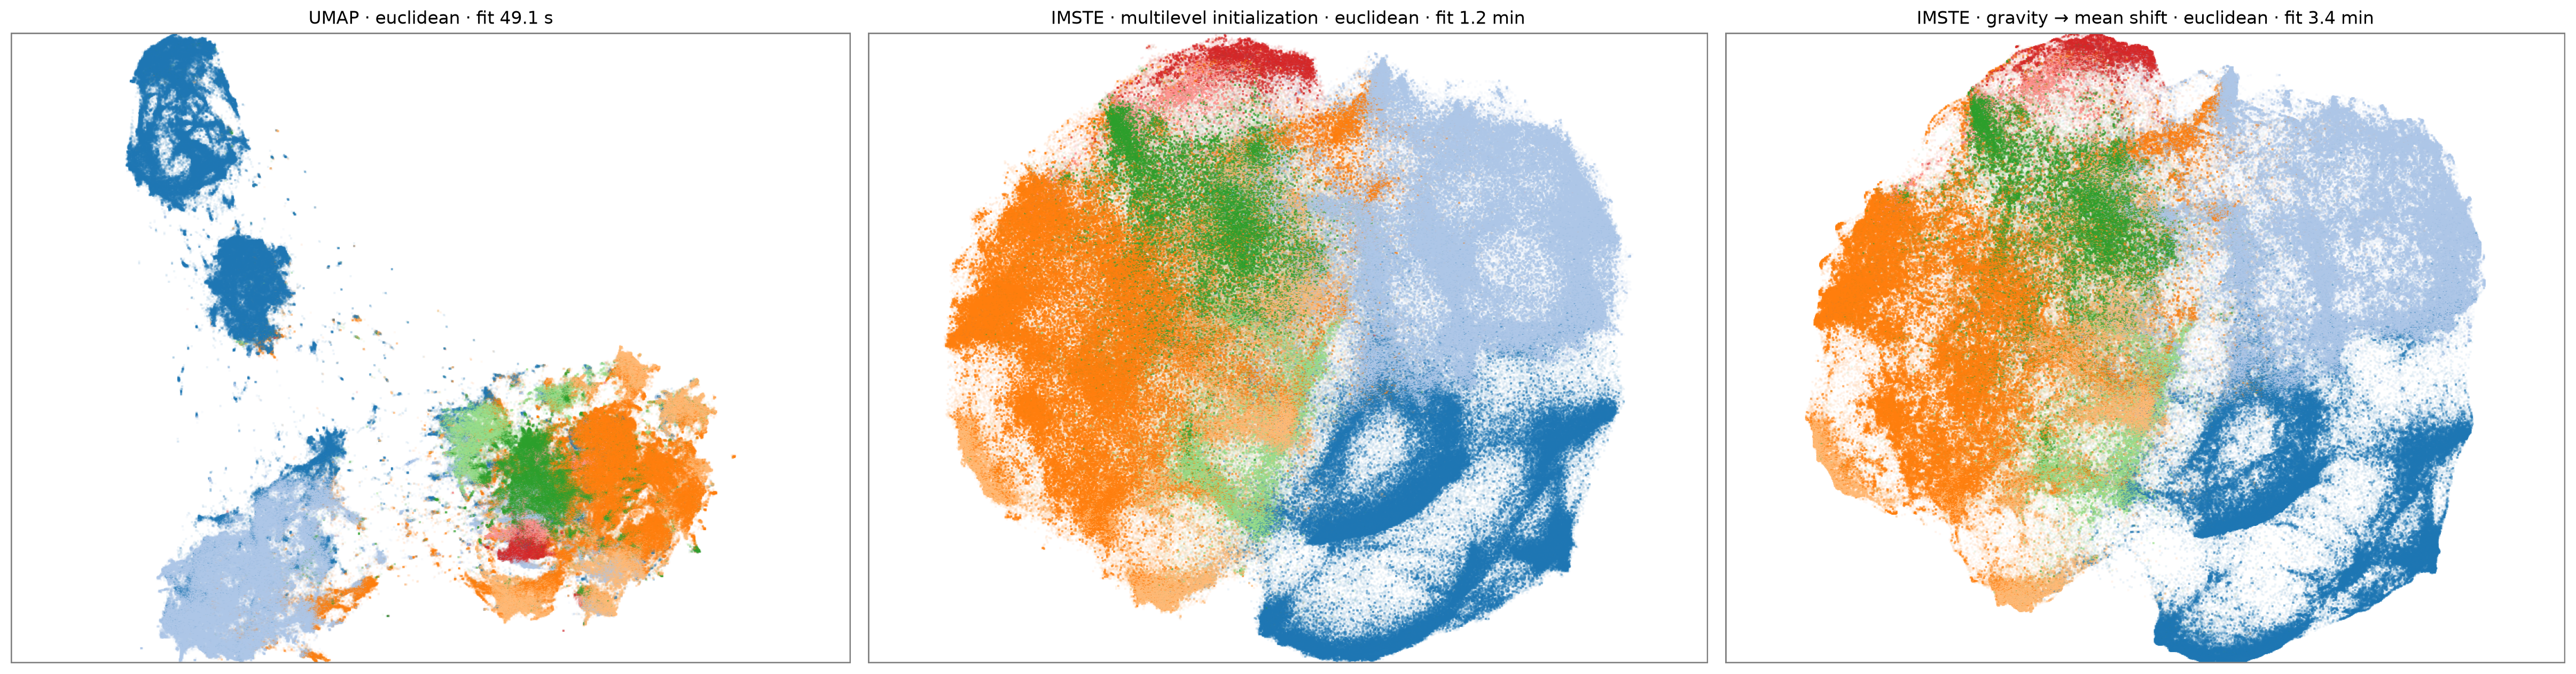

In [7]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display
import importlib
import imste.visualization as _imste_visualization
_imste_visualization = importlib.reload(_imste_visualization)
render_datashader_embedding = _imste_visualization.render_datashader_embedding

def render_embedding_preserving_aspect(embedding, labels=None, **kwargs):
    """Render without geometric stretching; support older IMSTE installs too."""
    import inspect
    options = dict(kwargs)
    renderer_parameters = inspect.signature(render_datashader_embedding).parameters
    if "preserve_aspect" in renderer_parameters:
        options["preserve_aspect"] = True
    else:
        coordinates = np.asarray(embedding)
        width = int(options.get("width", 1000))
        height = int(options.get("height", 1000))
        x_limits = np.asarray(
            options.get("x_range") or (coordinates[:, 0].min(), coordinates[:, 0].max()),
            dtype=np.float64,
        )
        y_limits = np.asarray(
            options.get("y_range") or (coordinates[:, 1].min(), coordinates[:, 1].max()),
            dtype=np.float64,
        )
        pixel_scale = max(
            (x_limits[1] - x_limits[0]) / width,
            (y_limits[1] - y_limits[0]) / height,
            np.finfo(np.float64).eps,
        )
        x_center, y_center = float(x_limits.mean()), float(y_limits.mean())
        options["x_range"] = (
            x_center - pixel_scale * width / 2,
            x_center + pixel_scale * width / 2,
        )
        options["y_range"] = (
            y_center - pixel_scale * height / 2,
            y_center + pixel_scale * height / 2,
        )
    return render_datashader_embedding(embedding, labels, **options)


domain_order = list(labels.categories)
palette = plt.get_cmap("tab20")
domain_color_key = {
    domain: to_hex(palette(index % palette.N))
    for index, domain in enumerate(domain_order)
}
label_values = labels.astype(str)
layouts = [
    ("UMAP", Z_umap, umap_seconds),
    ("IMSTE · multilevel initialization", Z_imste_base, imste_seconds),
]
if IMSTE_GRAVITY_ENABLED or IMSTE_MEAN_SHIFT_ITERATIONS > 0:
    layouts.append(("IMSTE · gravity → mean shift", Z_imste, imste_seconds + gravity_seconds + mean_shift_seconds))

fig, axes = plt.subplots(1, len(layouts), figsize=(8 * len(layouts), 7), constrained_layout=True, squeeze=False)
for ax, (method, coordinates, seconds) in zip(axes.ravel(), layouts):
    image = render_embedding_preserving_aspect(
        coordinates[:, :2], label_values, width=1200, height=900,
        color_key=domain_color_key, min_alpha=20, background="white",
        spread_px=1,
    )
    ax.imshow(image.to_pil())
    runtime = f"{seconds / 60:.1f} min" if seconds >= 60 else f"{seconds:.1f} s"
    ax.set_title(f"{method} · {METRIC} · fit {runtime}")
    ax.set_axis_off()
display(fig)
plt.close(fig)
